# 01 — Mechanistic ablation: attention heads, neurons, and layers

**`01_mechanistic_ablation.ipynb`** — inside the network: zero out individual attention heads, MLP neurons, or whole layers, and measure the effect on the model's predictions.

A transformer is built out of a stack of attention heads and MLP neurons, all adding their contribution into a shared residual stream. The classic mechanistic-interpretability move is: **zero out one piece, see what breaks.** If removing head 14 in layer 9 tanks the model's ability to recall a fact, that head was probably doing something related to retrieving that fact.

We'll do this three ways:

1. **Factual recall** — ablate every single attention head, one at a time, and plot how much each one matters for "The capital of France is **Paris**."
2. **Zero vs. mean ablation** — zeroing a head is a bigger, cruder intervention than it looks; compare it against a gentler "mean ablation" baseline.
3. **An IOI-style task** — the classic "indirect object identification" task from the mechanistic-interpretability literature, as an open-ended exploration rather than a guaranteed reproduction.

All of the ablation machinery (`ablate_heads`, `ablate_neurons`, `ablate_layer`) works by registering a temporary forward hook on the model and removing it again afterwards — nothing here modifies the model's weights.

In [1]:
try:
    # model loader
    from llm_ablation.models import load_model
    # model hook points
    from llm_ablation.hooks import ablate_heads, collect_activations, head_hook_point
    # ablation utilities
    from llm_ablation.mech import (
        logit_diff,
        run_factual_recall_task,
        run_ioi_style_task,
        top_heads,
    )
    # for visualization
    from llm_ablation.plot import plot_ablation_heatmap
except Exception as e:
    raise(e)

# load synthetic data
from llm_ablation.data import (
    FACTUAL_RECALL_PAIRS,
    GENERAL_KNOWLEDGE_RECALL_PAIRS,
    IOI_STYLE_TEMPLATES
)

# load model chekpoint
bundle = load_model()
print(f"{bundle.name}: {bundle.n_layers} layers x {bundle.n_heads} heads")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen/Qwen2.5-0.5B-Instruct: 24 layers x 14 heads


## 1. Factual recall: which heads does "The capital of XXX is YYY" depend on?

Now we estimate how much every single head contributes to the response with respect of a specific prompt domain.

The `logit_diff` function measures how much more likely the correct completion is than a plausible wrong one — here, `Paris` vs. `London` for example.

A large positive difference means the model is confident and correct.

Note that for other types of knowledge domain, the model may not be so sure to begin with: it might depend on the training data, the quality of the prompt or the topic type itself.

In [2]:
# test the base use case: City Capitals
print(f"Domain Topic: {len(FACTUAL_RECALL_PAIRS)}")
for prompt, correct, incorrect in FACTUAL_RECALL_PAIRS:
    diff = logit_diff(bundle, prompt, correct, incorrect)
    print(f"{diff:6.2f}  {prompt} -> {correct} (vs {incorrect})")

# compute also for general knowledge
print(f"General Knowledge Topics: {len(GENERAL_KNOWLEDGE_RECALL_PAIRS)}")
for prompt, correct, incorrect in GENERAL_KNOWLEDGE_RECALL_PAIRS:
    diff = logit_diff(bundle, prompt, correct, incorrect)
    print(f"{diff:6.2f}  {prompt} -> {correct} (vs {incorrect})")

Domain Topic: 5
  6.08  The capital of France is -> Paris (vs London)
  6.20  The capital of Japan is -> Tokyo (vs Seoul)
  5.94  The capital of Italy is -> Rome (vs Madrid)
  6.45  The capital of Germany is -> Berlin (vs Vienna)
  7.53  The capital of Egypt is -> Cairo (vs Baghdad)
General Knowledge Topics: 3
  0.61  The name of the matemathician Cantor was -> Georg (vs Hans)
  6.46  A black hole is the remnant of a dead -> star (vs galaxy)
  2.82  The sunset sky is -> red (vs green)


Now the computationally expensive part: Recall now how the model is built.

In [3]:
# display structure
from torchinfo import summary

# generate model summary
input_tensor = bundle.tokenizer("this is a question, don't you agree?")
model_summary = summary(bundle.model, input_ids=input_tensor.get('input_ids'))

# display
print(bundle.model)
print(model_summary)

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

Ablate every `(layer, head)` pair one at a time and record how much the logit-diff *drops* when that head is missing. With 24 layers x 14 heads and 5 prompts, this is ~1700 forward passes — a minute or so on CPU.

[ZERO SWEEP] mean baseline logit diff: 6.44


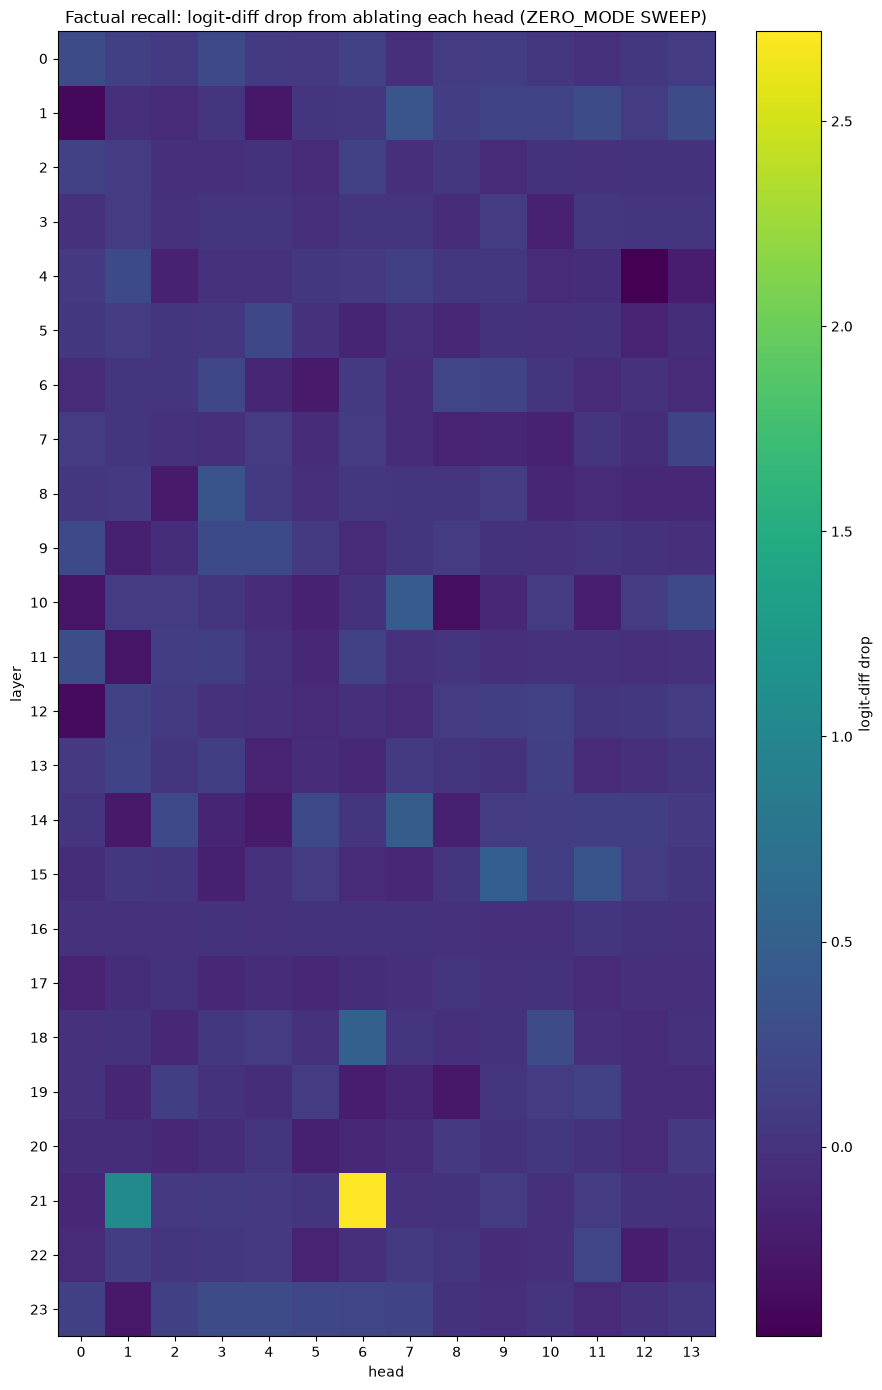

In [4]:
# run ablation sweep "Zero" mode
zero_mode_result = run_factual_recall_task(bundle, FACTUAL_RECALL_PAIRS)
print(f"[ZERO SWEEP] mean baseline logit diff: {zero_mode_result['mean_baseline_logit_diff']:.2f}")

# display heatmap for every layer,head
title = "Factual recall: logit-diff drop from ablating each head (ZERO_MODE SWEEP)"
fig = plot_ablation_heatmap(zero_mode_result["head_ablation_drop"], title=title)

In [5]:
# identify the most impacting heads
print("Top 5 most important heads (layer, head, logit-diff drop):")
for layer, head, drop in top_heads(zero_mode_result["head_ablation_drop"], k=5):
    print(f"  layer {layer:2d}, head {head:2d}: drop = {drop:.3f}")

Top 5 most important heads (layer, head, logit-diff drop):
  layer 21, head  6: drop = 2.719
  layer 21, head  1: drop = 1.042
  layer 18, head  6: drop = 0.511
  layer 15, head  9: drop = 0.493
  layer 14, head  7: drop = 0.473


Most of the heatmap is near zero with a handful of head contributions standing out sharply.

That's the point: **a small number of heads carry most of the "knows the capital" behavior**, and ablating the rest barely moves the needle.

## 2. Zero ablation vs. mean ablation

Setting an activation to exactly zero is a strong, somewhat unnatural intervention — the model may never see that activation pattern during normal operation: it is not usual that an entire head is zeroed out (e.g. no activations).

A gentler alternative is **mean ablation**: replace the head's output with its *average* value over some baseline prompts, rather than zero. This usually makes a head's measured importance look smaller, which is itself a useful thing to know before trusting a zero-ablation result.

We'll compare both on the single most important head found above.

In [6]:
# get the most impactful layer/head combo from the "zero-ablation" experiment
top_layer, top_head, _ = top_heads(zero_mode_result["head_ablation_drop"], k=1)[0]

# sample the activation distribution for that layer/head and a baseline prompt set
baseline_prompts = [p for p, _, _ in FACTUAL_RECALL_PAIRS]
reference_cache = collect_activations(bundle, baseline_prompts, [head_hook_point(top_layer)])

# perform ablation and calculate logit diffs between outputs of zero and mean modes
prompt, correct, incorrect = FACTUAL_RECALL_PAIRS[0]
baseline = logit_diff(bundle, prompt, correct, incorrect)
with ablate_heads(bundle, top_layer, [top_head], mode="zero"):
    zero_ablated = logit_diff(bundle, prompt, correct, incorrect)
with ablate_heads(bundle, top_layer, [top_head], mode="mean", reference_cache=reference_cache):
    mean_ablated = logit_diff(bundle, prompt, correct, incorrect)

# display results
print(f"layer {top_layer}, head {top_head}")
print(f"  baseline:      {baseline:.2f}")
print(f"  zero-ablated:  {zero_ablated:.2f}  (drop = {baseline - zero_ablated:.2f})")
print(f"  mean-ablated:  {mean_ablated:.2f}  (drop = {baseline - mean_ablated:.2f})")

layer 21, head 6
  baseline:      6.08
  zero-ablated:  4.77  (drop = 1.30)
  mean-ablated:  5.08  (drop = 1.00)


Now let's try to evaluate a full ablation sweep using "mean" and "resample" methods

[MEAN SWEEP] mean baseline logit diff: 6.44


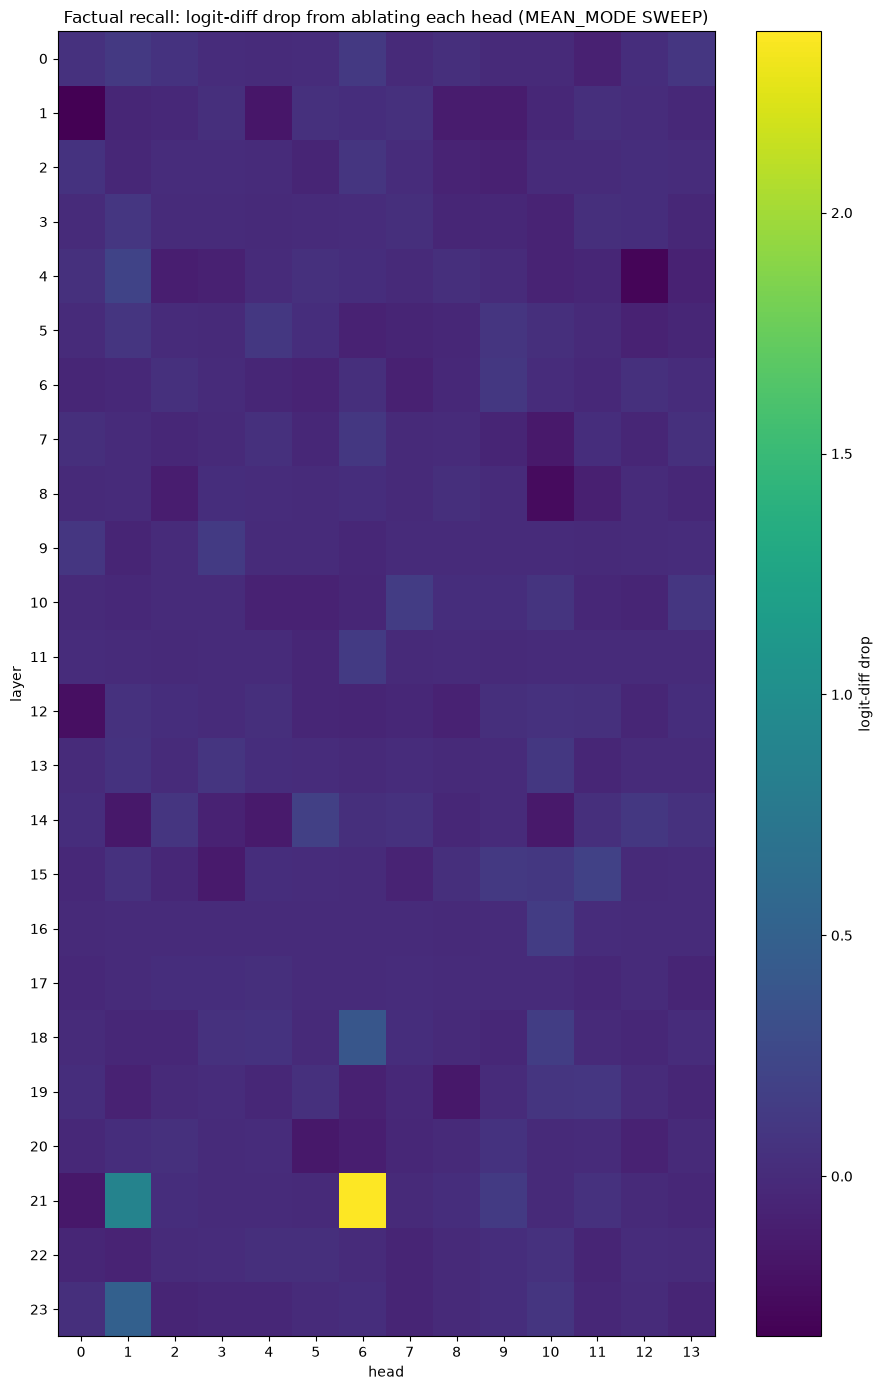

In [7]:
# run ablation sweep "Mean" mode
mean_mode_result = run_factual_recall_task(bundle, FACTUAL_RECALL_PAIRS, mode="mean")
print(f"[MEAN SWEEP] mean baseline logit diff: {mean_mode_result['mean_baseline_logit_diff']:.2f}")

# display heatmap for every layer,head
title = "Factual recall: logit-diff drop from ablating each head (MEAN_MODE SWEEP)"
fig = plot_ablation_heatmap(mean_mode_result["head_ablation_drop"], title=title)

In [8]:
# identify the most impacting heads
print("Top 5 most important heads (layer, head, logit-diff drop):")
for layer, head, drop in top_heads(mean_mode_result["head_ablation_drop"], k=5):
    print(f"  layer {layer:2d}, head {head:2d}: drop = {drop:.3f}")

Top 5 most important heads (layer, head, logit-diff drop):
  layer 21, head  6: drop = 2.377
  layer 21, head  1: drop = 0.878
  layer 23, head  1: drop = 0.503
  layer 18, head  6: drop = 0.389
  layer  4, head  1: drop = 0.209


[RESAMPLE SWEEP] mean baseline logit diff: 6.44


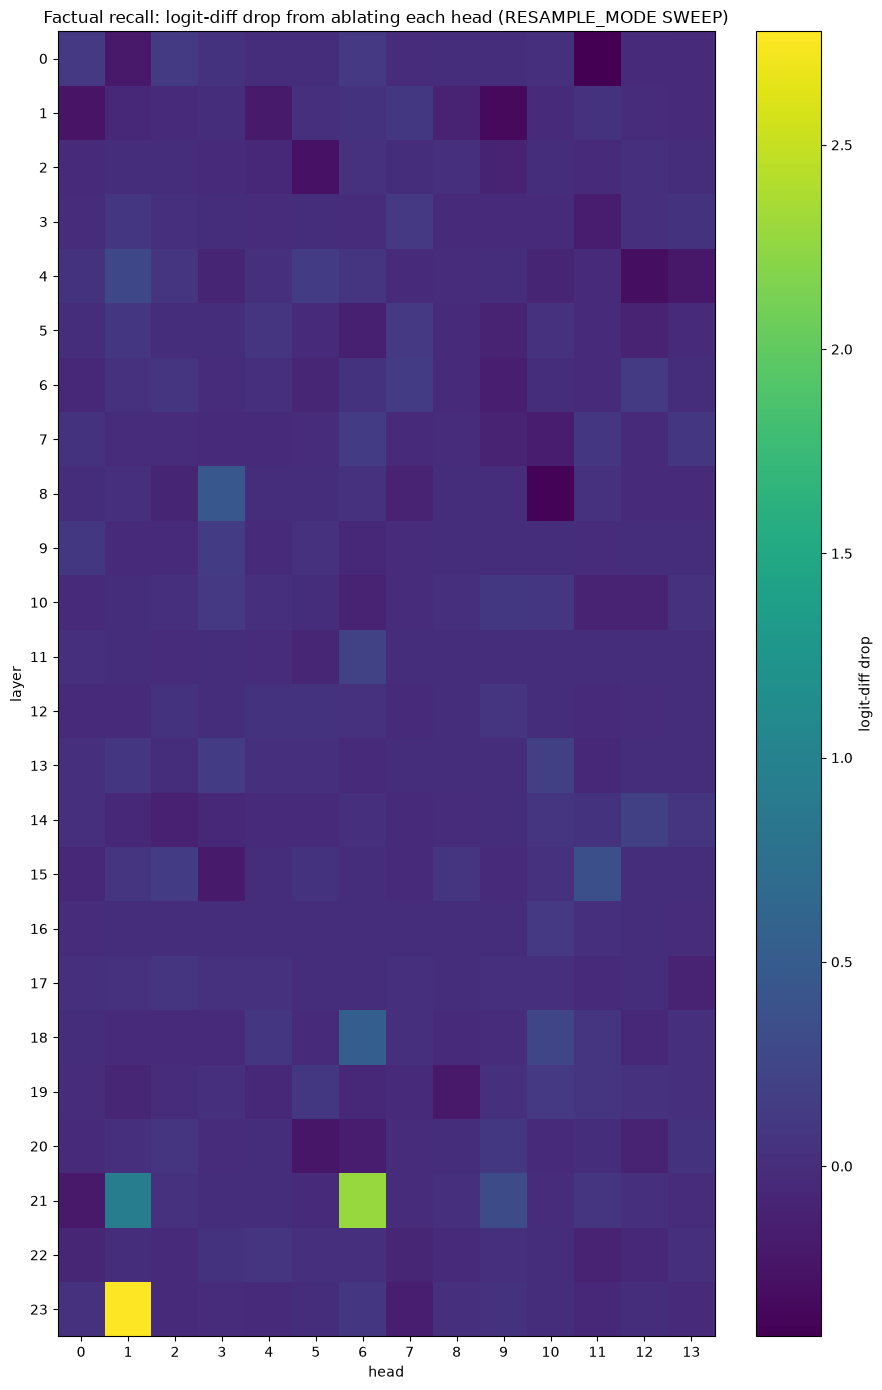

In [9]:
# run ablation sweep "Resample" mode
resample_mode_result = run_factual_recall_task(bundle, FACTUAL_RECALL_PAIRS, mode="resample")
print(f"[RESAMPLE SWEEP] mean baseline logit diff: {resample_mode_result['mean_baseline_logit_diff']:.2f}")

# display heatmap for every layer,head
title = "Factual recall: logit-diff drop from ablating each head (RESAMPLE_MODE SWEEP)"
fig = plot_ablation_heatmap(resample_mode_result["head_ablation_drop"], title=title)

In [10]:
# identify the most impacting heads
print("Top 5 most important heads (layer, head, logit-diff drop):")
for layer, head, drop in top_heads(resample_mode_result["head_ablation_drop"], k=5):
    print(f"  layer {layer:2d}, head {head:2d}: drop = {drop:.3f}")

Top 5 most important heads (layer, head, logit-diff drop):
  layer 23, head  1: drop = 2.778
  layer 21, head  6: drop = 2.280
  layer 21, head  1: drop = 0.942
  layer 18, head  6: drop = 0.544
  layer  8, head  3: drop = 0.455


## Results comparison

Let's compare results across the three head ablation options: import matplotlib and gather results from previous steps

In [11]:
try:
    import numpy as np
    from matplotlib.figure import Figure
    import matplotlib.pyplot as plt
except Exception as e:
    raise(e)

# heatmaps
ablation_results = [
    zero_mode_result,
    mean_mode_result,
    resample_mode_result
]

### Plot Ablation Heatmaps (Zero/Mean/Resample)

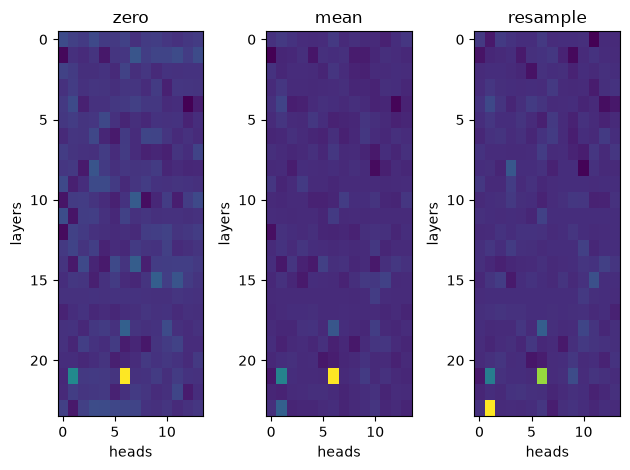

In [12]:
# draw side by side
fig, ax = plt.subplots(1,3)
for i,d in enumerate(ablation_results):
    ax[i].set_title(d["ablation_mode"])
    ax[i].set_xlabel("heads")
    ax[i].set_ylabel("layers")
    ax[i].imshow(d["head_ablation_drop"], aspect="auto", cmap="viridis")
    
# prepare graph
fig.tight_layout()

### Plot Top-K Heads

In [13]:
# top K heads responsible for answering a specific prompt set
top_K: int = 5

# logit drop values
logit_drop_values = {
    "zero": top_heads(zero_mode_result["head_ablation_drop"], k=top_K),
    "mean": top_heads(mean_mode_result["head_ablation_drop"], k=top_K),
    "resample": top_heads(resample_mode_result["head_ablation_drop"], k=top_K),
}

# display values
from pprint import pprint
pprint(logit_drop_values)

{'mean': [(21, 6, 2.3765625),
          (21, 1, 0.878125),
          (23, 1, 0.503125),
          (18, 6, 0.3890625),
          (4, 1, 0.209375)],
 'resample': [(23, 1, 2.778125),
              (21, 6, 2.2796875),
              (21, 1, 0.9421875),
              (18, 6, 0.54375),
              (8, 3, 0.4546875)],
 'zero': [(21, 6, 2.71875),
          (21, 1, 1.0421875),
          (18, 6, 0.5109375),
          (15, 9, 0.49296875),
          (14, 7, 0.4734375)]}


In [14]:
# extract data points
def datapoints(tp: List):
    # extract x, y, v axes
    x = [v[0] for v in tp]
    y = [v[1] for v in tp]
    v = [v[2] for v in tp]

    # return
    return x, y, v


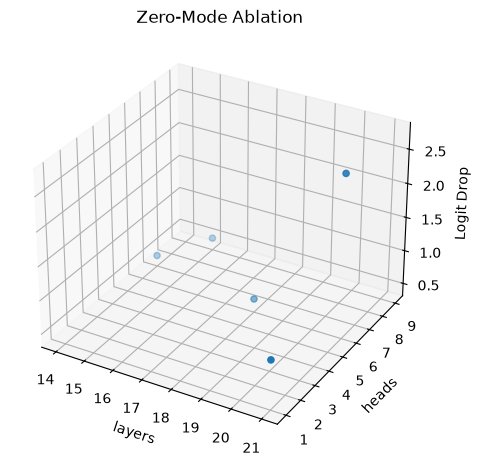

In [15]:
# draw side by side
fig = plt.figure()
# zero ablation
zero_ax = fig.add_subplot(projection="3d")
zero_ax.set_title("Zero-Mode Ablation")
zero_ax.set_xlabel("layers")
zero_ax.set_ylabel("heads")
zero_ax.set_zlabel("Logit Drop")
x, y, v = datapoints(logit_drop_values["zero"])
zero_ax.scatter(
    xs=x, ys=y, zs=v, mouseover=True
)
# prepare graph
fig.tight_layout()

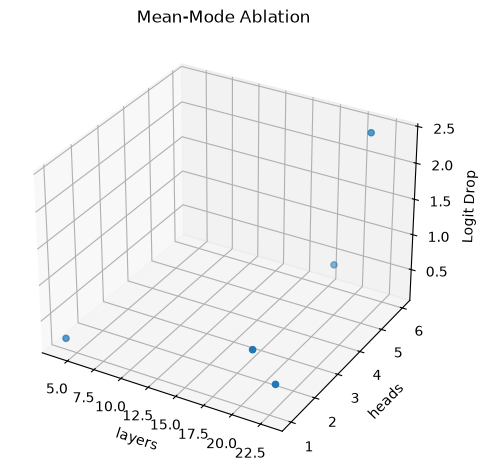

In [16]:
# draw side by side
fig = plt.figure()
# mean ablation
mean_ax = fig.add_subplot(projection="3d")
mean_ax.set_title("Mean-Mode Ablation")
mean_ax.set_xlabel("layers")
mean_ax.set_ylabel("heads")
mean_ax.set_zlabel("Logit Drop")
x, y, v = datapoints(logit_drop_values["mean"])
mean_ax.scatter(
    xs=x, ys=y, zs=v, mouseover=True
)
# prepare graph
fig.tight_layout()

## 3. An IOI-style task (exploratory)

The "indirect object identification" task — "When Mary and John went to the store, John gave a drink to **___**" (answer: Mary) — is one of the best-studied circuits in mechanistic interpretability, but that work was done on GPT-2-small. This is a small, *instruction-tuned* model with a different architecture, so treat what follows as "let's go look," not a guaranteed reproduction of the textbook result.

  5.78  ... went to the store, John gave a drink to -> Mary (vs John)
  8.45  ...b went to the park, Bob gave the ball to -> Alice (vs Bob)
  4.15  ... left the office, Sam handed the keys to -> Tom (vs Sam)
 11.60  ...ere at the cafe, Liam passed the menu to -> Emma (vs Liam)


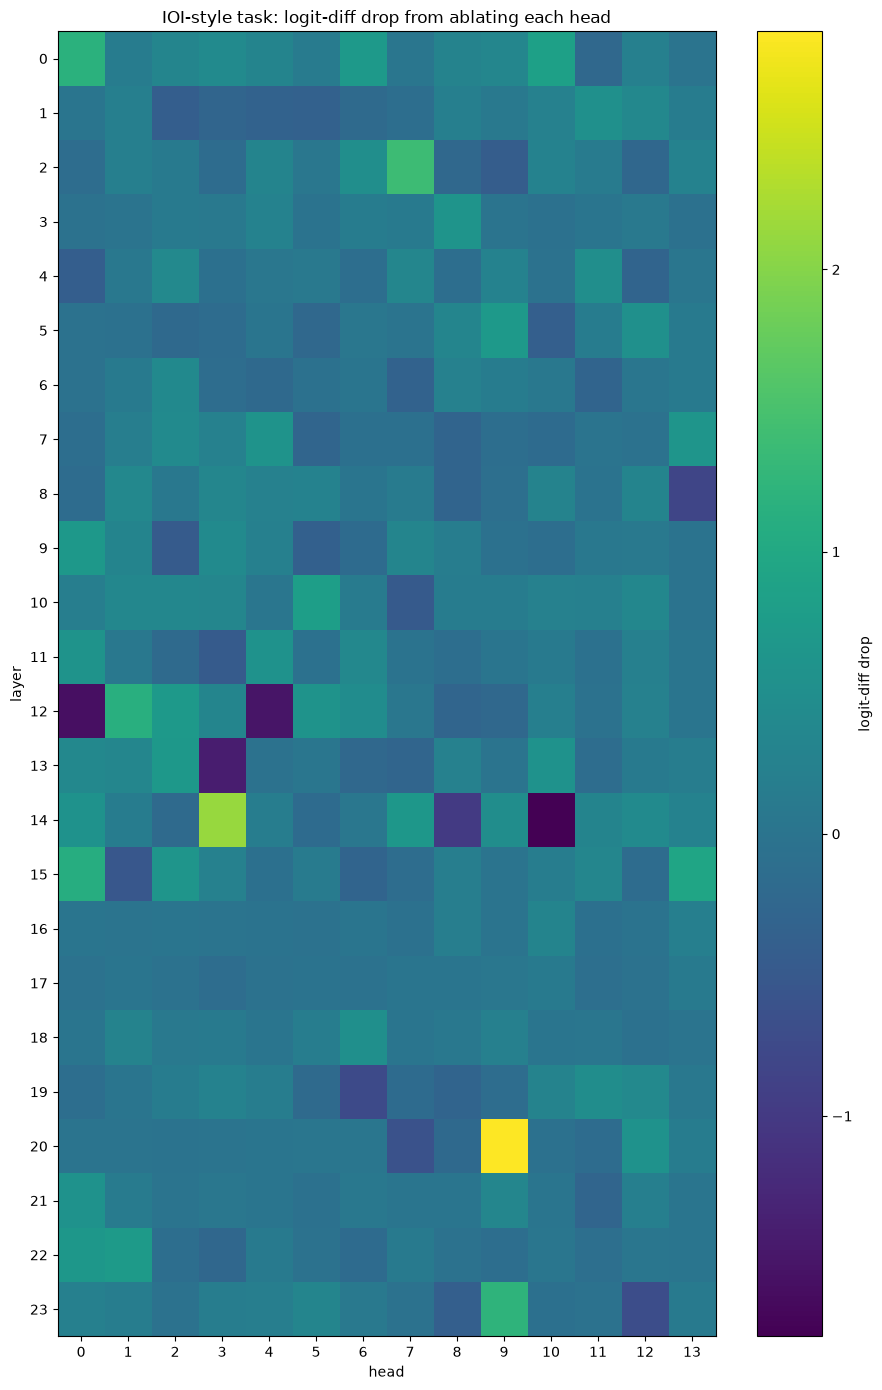

In [17]:
for prompt, correct, incorrect in IOI_STYLE_TEMPLATES:
    diff = logit_diff(bundle, prompt, correct, incorrect)
    print(f"{diff:6.2f}  ...{prompt[-40:]} -> {correct} (vs {incorrect})")

ioi_result = run_ioi_style_task(bundle, IOI_STYLE_TEMPLATES)
title = "IOI-style task: logit-diff drop from ablating each head"
fig = plot_ablation_heatmap(ioi_result["head_ablation_drop"], title=title)

In [18]:
print("Top 5 heads for the IOI-style task:")
for layer, head, drop in top_heads(ioi_result["head_ablation_drop"], k=5):
    print(f"  layer {layer:2d}, head {head:2d}: drop = {drop:.3f}")

Top 5 heads for the IOI-style task:
  layer 20, head  9: drop = 2.844
  layer 14, head  3: drop = 2.127
  layer  2, head  7: drop = 1.395
  layer 23, head  9: drop = 1.232
  layer  0, head  0: drop = 1.170


Compare this top-5 list with the factual-recall one above — are they the same heads, or different ones? Either answer is informative: shared heads would suggest a general-purpose "look up the right entity" mechanism; disjoint heads would suggest the two tasks lean on genuinely different circuitry.